In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.neighbors import NearestNeighbors

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Books.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/DeepRec.png
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Ratings.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Users.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/classicRec.png
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/recsys_taxonomy2.png


In [6]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Books.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/DeepRec.png
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Ratings.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/Users.csv
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/classicRec.png
/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset/recsys_taxonomy2.png


In [9]:
dataset_path = '/kaggle/input/datasets/shivanshikaranjai/book-recommendation-dataset'

books = pd.read_csv(
    dataset_path + '/Books.csv',
    encoding='latin-1',
    low_memory=False
)

users = pd.read_csv(
    dataset_path + '/Users.csv',
    encoding='latin-1'
)

ratings = pd.read_csv(
    dataset_path + '/Ratings.csv',
    encoding='latin-1'
)

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [10]:
print("BOOKS DATASET")
display(books.head())

print("USERS DATASET")
display(users.head())

print("RATINGS DATASET")
display(ratings.head())

BOOKS DATASET


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
0,0195153448,Classical Mythology,Mark P. O. Morford,2002,Oxford University Press,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...,http://images.amazon.com/images/P/0195153448.0...
1,0002005018,Clara Callan,Richard Bruce Wright,2001,HarperFlamingo Canada,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...,http://images.amazon.com/images/P/0002005018.0...
2,0060973129,Decision in Normandy,Carlo D'Este,1991,HarperPerennial,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...,http://images.amazon.com/images/P/0060973129.0...
3,0374157065,Flu: The Story of the Great Influenza Pandemic...,Gina Bari Kolata,1999,Farrar Straus Giroux,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...,http://images.amazon.com/images/P/0374157065.0...
4,0393045218,The Mummies of Urumchi,E. J. W. Barber,1999,W. W. Norton &amp; Company,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...,http://images.amazon.com/images/P/0393045218.0...


USERS DATASET


,User-ID,Location,Age
0,1,"nyc, new york, usa",NaN
1,2,"stockton, california, usa",18.0
2,3,"moscow, yukon territory, russia",NaN
3,4,"porto, v.n.gaia, portugal",17.0
4,5,"farnborough, hants, united kingdom",NaN


RATINGS DATASET


,User-ID,ISBN,Book-Rating
0,276725,034545104X,0
1,276726,0155061224,5
2,276727,0446520802,0
3,276729,052165615X,3
4,276729,0521795028,6


In [11]:
print("Books Shape:", books.shape)
print("Users Shape:", users.shape)
print("Ratings Shape:", ratings.shape)

Books Shape: (271360, 8)
Users Shape: (278858, 3)
Ratings Shape: (1149780, 3)


In [12]:
print("Books Information:")
books.info()

print("\nUsers Information:")
users.info()

print("\nRatings Information:")
ratings.info()

Books Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 271360 entries, 0 to 271359
Data columns (total 8 columns):
 #   Column               Non-Null Count   Dtype 
---  ------               --------------   ----- 
 0   ISBN                 271360 non-null  object
 1   Book-Title           271360 non-null  object
 2   Book-Author          271358 non-null  object
 3   Year-Of-Publication  271360 non-null  object
 4   Publisher            271358 non-null  object
 5   Image-URL-S          271360 non-null  object
 6   Image-URL-M          271360 non-null  object
 7   Image-URL-L          271357 non-null  object
dtypes: object(8)
memory usage: 16.6+ MB

Users Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 278858 entries, 0 to 278857
Data columns (total 3 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   User-ID   278858 non-null  int64  
 1   Location  278858 non-null  object 
 2   Age       168096 non-null  float64


In [20]:
print("Missing Values in Books:")
print(books.isnull().sum())

print("\nMissing Values in Users:")
print(users.isnull().sum())

print("\nMissing Values in Ratings:")
print(ratings.isnull().sum())

Missing Values in Books:
ISBN                   0
Book-Title             0
Book-Author            2
Year-Of-Publication    0
Publisher              2
Image-URL-S            0
Image-URL-M            0
Image-URL-L            3
dtype: int64

Missing Values in Users:
User-ID          0
Location         0
Age         110762
dtype: int64

Missing Values in Ratings:
User-ID        0
ISBN           0
Book-Rating    0
dtype: int64


In [23]:
print("Books Description:")
display(books.describe(include='all'))

print("Ratings Description:")
display(ratings.describe())

Books Description:


,ISBN,Book-Title,Book-Author,Year-Of-Publication,Publisher,Image-URL-S,Image-URL-M,Image-URL-L
count,271360,271360,271358,271360,271358,271360,271360,271357
unique,271360,242135,102022,118,16807,271044,271044,271041
top,020130998X,Selected Poems,Agatha Christie,2002,Harlequin,http://images.amazon.com/images/P/042509474X.0...,http://images.amazon.com/images/P/042509474X.0...,http://images.amazon.com/images/P/006091985X.0...
freq,1,27,632,17627,7535,2,2,2


Ratings Description:


,User-ID,Book-Rating
count,1.149780e+06,1.149780e+06
mean,1.403864e+05,2.866950e+00
std,8.056228e+04,3.854184e+00
min,2.000000e+00,0.000000e+00
25%,7.034500e+04,0.000000e+00
50%,1.410100e+05,0.000000e+00
75%,2.110280e+05,7.000000e+00
max,2.788540e+05,1.000000e+01


In [24]:
books.drop_duplicates(inplace=True)
users.drop_duplicates(inplace=True)
ratings.drop_duplicates(inplace=True)

print("Duplicate records removed!")

Duplicate records removed!


In [25]:
books.dropna(
    subset=['ISBN', 'Book-Title', 'Book-Author'],
    inplace=True
)

ratings.dropna(
    subset=['User-ID', 'ISBN', 'Book-Rating'],
    inplace=True
)

books['Book-Title'] = books['Book-Title'].astype(str).str.strip()

books['Book-Author'] = books['Book-Author'].astype(str).str.strip()

books['Publisher'] = books['Publisher'].fillna('Unknown')

print("Missing values handled successfully!")

Missing values handled successfully!


In [27]:
books['Year-Of-Publication'] = pd.to_numeric(
    books['Year-Of-Publication'],
    errors='coerce'
)

ratings['Book-Rating'] = pd.to_numeric(
    ratings['Book-Rating'],
    errors='coerce'
)

ratings['User-ID'] = pd.to_numeric(
    ratings['User-ID'],
    errors='coerce'
)

ratings.dropna(
    subset=['User-ID', 'Book-Rating'],
    inplace=True
)

ratings['User-ID'] = ratings['User-ID'].astype(int)

ratings['Book-Rating'] = ratings['Book-Rating'].astype(float)

print("Data types converted successfully!")

Data types converted successfully!


In [29]:
books = books[
    books['Year-Of-Publication'].between(1000, 2026)
].copy()

ratings = ratings[
    ratings['Book-Rating'].between(0, 10)
].copy()

books['Year-Of-Publication'] = (
    books['Year-Of-Publication'].astype(int)
)

print("Invalid records removed!")

Invalid records removed!


In [30]:
books = books.drop_duplicates(
    subset='ISBN',
    keep='first'
)

print("Unique books:", books.shape[0])
print("Total ratings:", ratings.shape[0])

Unique books: 266726
Total ratings: 1149780


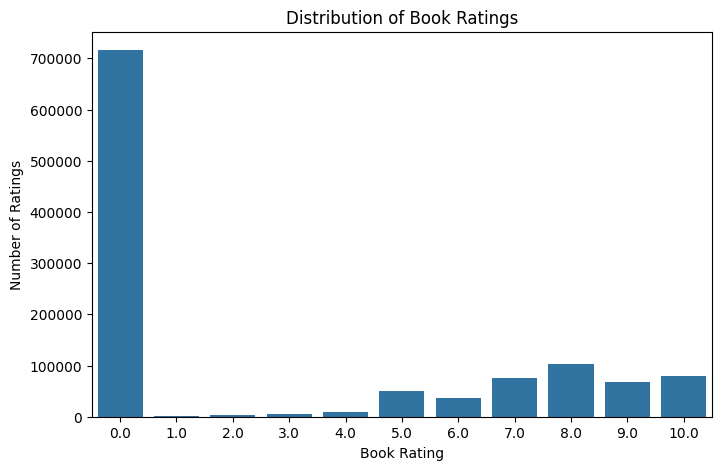

In [31]:
plt.figure(figsize=(8, 5))

sns.countplot(
    x='Book-Rating',
    data=ratings
)

plt.title("Distribution of Book Ratings")
plt.xlabel("Book Rating")
plt.ylabel("Number of Ratings")

plt.show()

In [32]:
top_books = ratings['ISBN'].value_counts().head(10)

print("Top 10 Most Rated Books:")
display(top_books)

Top 10 Most Rated Books:


ISBN
0971880107    2502
0316666343    1295
0385504209     883
0060928336     732
0312195516     723
044023722X     647
0679781587     639
0142001740     615
067976402X     614
0671027360     586
Name: count, dtype: int64

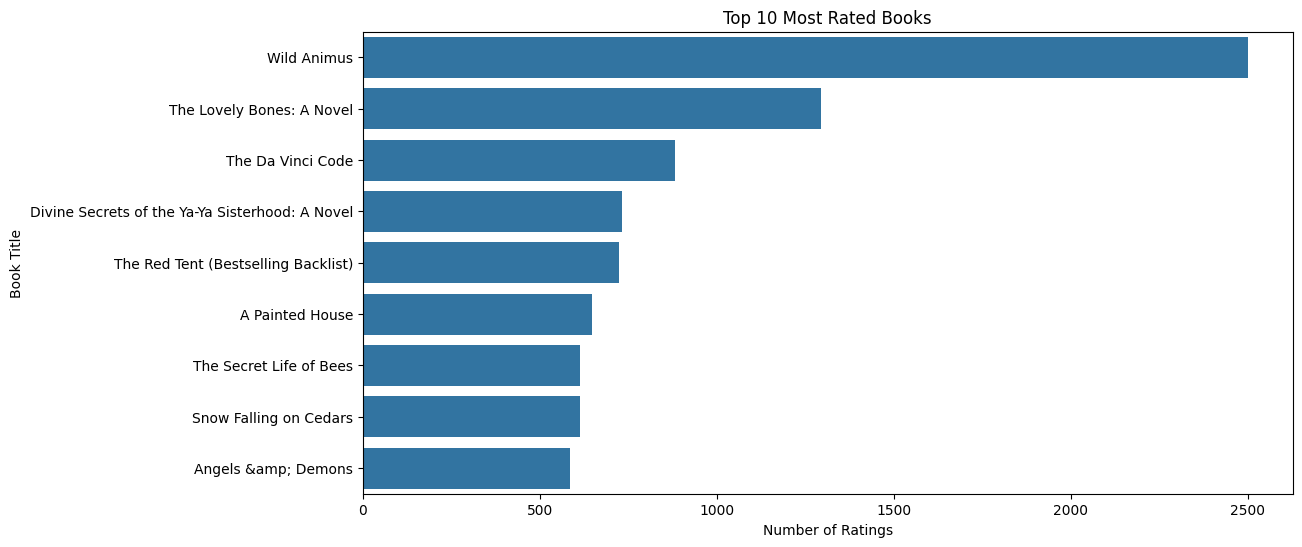

In [33]:
top_books_df = pd.merge(
    top_books.reset_index(),
    books,
    left_on='ISBN',
    right_on='ISBN'
)

top_books_df.rename(
    columns={'count': 'Number of Ratings'},
    inplace=True
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_books_df,
    x='Number of Ratings',
    y='Book-Title'
)

plt.title("Top 10 Most Rated Books")
plt.xlabel("Number of Ratings")
plt.ylabel("Book Title")

plt.show()

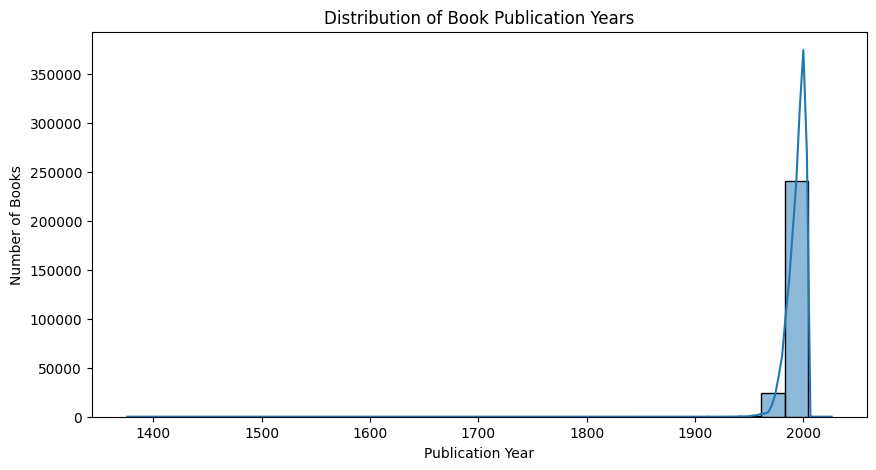

In [34]:
plt.figure(figsize=(10, 5))

sns.histplot(
    books['Year-Of-Publication'],
    bins=30,
    kde=True
)

plt.title("Distribution of Book Publication Years")
plt.xlabel("Publication Year")
plt.ylabel("Number of Books")

plt.show()

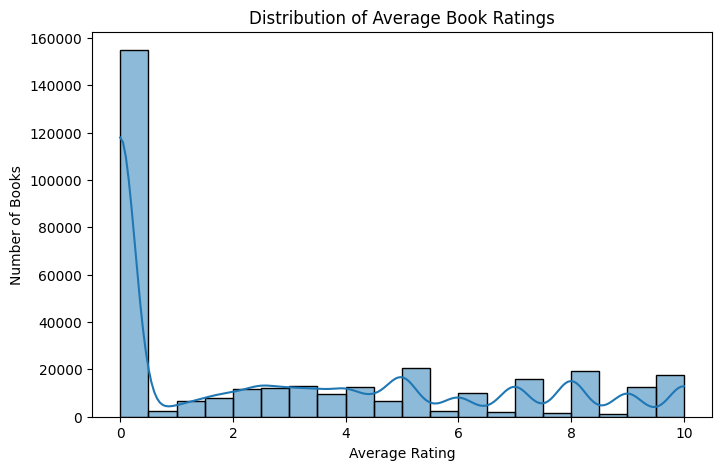

In [35]:
average_rating = ratings.groupby(
    'ISBN'
)['Book-Rating'].mean()

plt.figure(figsize=(8, 5))

sns.histplot(
    average_rating,
    bins=20,
    kde=True
)

plt.title("Distribution of Average Book Ratings")
plt.xlabel("Average Rating")
plt.ylabel("Number of Books")

plt.show()

In [36]:
rating_count = ratings.groupby('ISBN').size().reset_index(
    name='Rating-Count'
)

average_rating = ratings.groupby('ISBN')['Book-Rating'].mean().reset_index(
    name='Average-Rating'
)

book_popularity = pd.merge(
    rating_count,
    average_rating,
    on='ISBN'
)

book_popularity = pd.merge(
    book_popularity,
    books,
    on='ISBN'
)

book_popularity = book_popularity.sort_values(
    by='Rating-Count',
    ascending=False
)

display(
    book_popularity[
        ['Book-Title', 'Book-Author', 'Rating-Count', 'Average-Rating']
    ].head(10)
)

,Book-Title,Book-Author,Rating-Count,Average-Rating
213092,Wild Animus,Rich Shapero,2502,1.019584
37942,The Lovely Bones: A Novel,Alice Sebold,1295,4.468726
69833,The Da Vinci Code,Dan Brown,883,4.652322
7203,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,732,3.448087
31760,The Red Tent (Bestselling Backlist),Anita Diamant,723,4.334716
86318,A Painted House,John Grisham,647,3.187017
20876,The Secret Life of Bees,Sue Monk Kidd,615,4.219512
143128,Snow Falling on Cedars,David Guterson,614,3.255700
131262,Angels &amp; Demons,Dan Brown,586,3.718430
92701,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,585,4.105983


In [39]:
def popular_recommendations(n=10):

    result = book_popularity[
        book_popularity['Rating-Count'] >= 5
    ].sort_values(
        by=['Rating-Count', 'Average-Rating'],
        ascending=False
    )

    return result[
        ['Book-Title', 'Book-Author', 'Average-Rating', 'Rating-Count']
    ].head(n)

In [40]:
print("Top 10 Popular Books:")

display(popular_recommendations(10))

Top 10 Popular Books:


,Book-Title,Book-Author,Average-Rating,Rating-Count
213092,Wild Animus,Rich Shapero,1.019584,2502
37942,The Lovely Bones: A Novel,Alice Sebold,4.468726,1295
69833,The Da Vinci Code,Dan Brown,4.652322,883
7203,Divine Secrets of the Ya-Ya Sisterhood: A Novel,Rebecca Wells,3.448087,732
31760,The Red Tent (Bestselling Backlist),Anita Diamant,4.334716,723
86318,A Painted House,John Grisham,3.187017,647
20876,The Secret Life of Bees,Sue Monk Kidd,4.219512,615
143128,Snow Falling on Cedars,David Guterson,3.255700,614
131262,Angels &amp; Demons,Dan Brown,3.718430,586
92701,Where the Heart Is (Oprah's Book Club (Paperba...,Billie Letts,4.105983,585


In [41]:
books['Publisher'] = books['Publisher'].fillna('Unknown')

books['features'] = (
    books['Book-Title'].astype(str) + ' ' +
    books['Book-Author'].astype(str) + ' ' +
    books['Publisher'].astype(str)
)

display(books[['Book-Title', 'features']].head())

,Book-Title,features
0,Classical Mythology,Classical Mythology Mark P. O. Morford Oxford ...
1,Clara Callan,Clara Callan Richard Bruce Wright HarperFlamin...
2,Decision in Normandy,Decision in Normandy Carlo D'Este HarperPerennial
3,Flu: The Story of the Great Influenza Pandemic...,Flu: The Story of the Great Influenza Pandemic...
4,The Mummies of Urumchi,The Mummies of Urumchi E. J. W. Barber W. W. N...


In [42]:
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(books['features'])

print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (266726, 5000)


In [43]:
content_model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_neighbors=11
)

content_model.fit(tfidf_matrix)

print("Content-Based Model Trained Successfully!")

Content-Based Model Trained Successfully!


In [45]:
book_indices = pd.Series(
    books.index,
    index=books['Book-Title']
).drop_duplicates()

def recommend_books(book_name, n=10):

    if book_name not in book_indices:
        print("Book not found in dataset!")
        return

    idx = book_indices[book_name]

    distances, neighbors = content_model.kneighbors(
        tfidf_matrix[idx],
        n_neighbors=min(n + 1, len(books))
    )

    recommended_indices = neighbors.flatten()[1:]

    recommendations = books.iloc[recommended_indices][
        ['Book-Title', 'Book-Author', 'Publisher']
    ]

    return recommendations.reset_index(drop=True)

In [46]:
recommend_books(
    'Harry Potter and the Chamber of Secrets'
)

,Book-Title,Book-Author,Publisher
0,Miriam's Kitchen: A Memoir,Elizabeth Ehrlich,Penguin USA
1,In My Momma's Kitchen (Amistad),Jerdine Nolen,Amistad
2,Wordstruck: A Memoir,Robert MacNeil,Penguin Books
3,"More, Now, Again: A Memoir of Addiction",Elizabeth Wurtzel,Touchstone Books
4,Miriam's Song: A Memoir,Mark Mathabane,Free Press
5,Balsamroot: A Memoir,Mary Clearman Blew,Penguin Books
6,Apollo's Fault (Timeswept),Miriam Raftery,Leisure Books
7,"More, Now, Again: A Memoir of Addiction",Elizabeth Wurtzel,Simon &amp; Schuster
8,"More, Now, Again: A Memoir of Addiction",Elizabeth Wurtzel,Simon &amp; Schuster
9,Kitchen Privileges : A Memoir,Mary Higgins Clark,Pocket


In [47]:
print(books['Book-Title'].sample(10).to_string(index=False))

Reservations for Murder (Myers, Tim. Lighthouse...
            Game Plan (Harlequin Romance, No 3026)
                         Biology of microorganisms
Return to Love: Reflections on the Principles o...
    Killing Time (Inspector Bill Slider Mysteries)
Death in a Hammock (Five Star First Edition Mys...
Schach und Management: Wie man besser zum Zuge ...
     My Perfect Guy (Sweet Valley Jr. High No. 14)
                                      Spring Fires
Caroling Dusk: An Anthology of Verse by Black P...


In [48]:
collab_data = ratings[ratings['Book-Rating'] > 0].copy()

collab_data = collab_data[
    collab_data['ISBN'].isin(books['ISBN'])
]

print("Collaborative Dataset Shape:", collab_data.shape)

Collaborative Dataset Shape: (378035, 3)


In [49]:
book_counts = collab_data['ISBN'].value_counts()

popular_isbns = book_counts[
    book_counts >= 5
].index

collab_data = collab_data[
    collab_data['ISBN'].isin(popular_isbns)
]

user_counts = collab_data['User-ID'].value_counts()

active_users = user_counts[
    user_counts >= 3
].index

collab_data = collab_data[
    collab_data['User-ID'].isin(active_users)
]

print("Filtered Collaborative Dataset:", collab_data.shape)

Filtered Collaborative Dataset: (149687, 3)


In [50]:
from scipy.sparse import csr_matrix

collab_data = collab_data.drop_duplicates(
    subset=['User-ID', 'ISBN'],
    keep='last'
)

isbn_codes = pd.Categorical(
    collab_data['ISBN']
)

user_codes = pd.Categorical(
    collab_data['User-ID']
)

user_book_matrix = csr_matrix(
    (
        collab_data['Book-Rating'].values,
        (isbn_codes.codes, user_codes.codes)
    )
)

isbn_mapping = list(isbn_codes.categories)

print("User-Book Matrix Shape:", user_book_matrix.shape)

User-Book Matrix Shape: (13545, 12857)


In [51]:
collab_model = NearestNeighbors(
    metric='cosine',
    algorithm='brute',
    n_neighbors=min(6, user_book_matrix.shape[0])
)

collab_model.fit(user_book_matrix)

print("Collaborative Filtering Model Trained Successfully!")

Collaborative Filtering Model Trained Successfully!


In [52]:
def collaborative_recommend(isbn, n=5):

    if isbn not in isbn_mapping:
        print("Book ISBN not found!")
        return

    book_index = isbn_mapping.index(isbn)

    book_vector = user_book_matrix[book_index]

    distances, indices = collab_model.kneighbors(
        book_vector,
        n_neighbors=min(n + 1, len(isbn_mapping))
    )

    similar_isbns = [
        isbn_mapping[i]
        for i in indices.flatten()[1:]
    ]

    result = books[
        books['ISBN'].isin(similar_isbns)
    ][['ISBN', 'Book-Title', 'Book-Author']]

    return result.reset_index(drop=True)

In [53]:
sample_isbn = isbn_mapping[0]

print("Similar Books Based on User Ratings:")

display(collaborative_recommend(sample_isbn))

Similar Books Based on User Ratings:


,ISBN,Book-Title,Book-Author
0,8804342838,Due di due (Bestsellers),Andrea De Carlo
1,3446153950,Das Foucaultsche Pendel.,Umberto Eco
2,3446202692,"Eine Frau, Eine Wohnung, Ein Roman",Wilhelm Genazino
3,0020811853,POSTCARDS,E. Annie Proulx
4,0877853134,The Arrivals,Naomi Gladish Smith


In [55]:
def hybrid_recommend(book_name, n=10):

    if book_name not in book_indices:
        print("Book not found!")
        return

    idx = book_indices[book_name]

    distances, neighbors = content_model.kneighbors(
        tfidf_matrix[idx],
        n_neighbors=min(n + 20, len(books))
    )

    candidates = books.iloc[
        neighbors.flatten()[1:]
    ][['ISBN', 'Book-Title', 'Book-Author']].copy()

    candidates['Similarity'] = 1 - distances.flatten()[1:]

    candidates = candidates.merge(
        book_popularity[
            ['ISBN', 'Rating-Count', 'Average-Rating']
        ],
        on='ISBN',
        how='left'
    )

    candidates[['Rating-Count', 'Average-Rating']] = (
        candidates[['Rating-Count', 'Average-Rating']].fillna(0)
    )

    candidates['Popularity-Score'] = (
        candidates['Rating-Count'] /
        max(book_popularity['Rating-Count'].max(), 1)
    )

    candidates['Hybrid-Score'] = (
        0.7 * candidates['Similarity'] +
        0.3 * candidates['Popularity-Score']
    )

    return candidates.sort_values(
        'Hybrid-Score',
        ascending=False
    )[
        ['Book-Title', 'Book-Author', 'Similarity',
         'Rating-Count', 'Average-Rating', 'Hybrid-Score']
    ].head(n)

In [56]:
hybrid_recommend(
    'Harry Potter and the Chamber of Secrets'
)

,Book-Title,Book-Author,Similarity,Rating-Count,Average-Rating,Hybrid-Score
29,Modern Classics of Fantasy,Gardner Dozois,1.000000,1,0.000000,0.700120
0,Miriam's Kitchen: A Memoir,Elizabeth Ehrlich,0.939026,5,7.800000,0.657918
30,Modern Classics of Science Fiction,Gardner Dozois,0.763672,2,0.000000,0.534810
31,Death of a Fantasy Life,T. G. Gilpin,0.604200,1,0.000000,0.423060
32,On Modern Marriage and Other Observations,Isak Dinesen,0.578702,1,0.000000,0.405212
42,Tully,Paullina Simons,0.568211,6,8.166667,0.398467
34,Interface Masque,Shariann Lewitt,0.568211,2,0.000000,0.397988
41,Nightshades,Bill Pronzini,0.568211,2,0.000000,0.397988
37,Schedule Two (Schedule 2),Gaylord Dold,0.568211,2,3.500000,0.397988
36,Regarding Roderer,Guillermo Martinez,0.568211,1,0.000000,0.397868


In [57]:
comparison = pd.DataFrame({
    'Recommendation Model': [
        'Popularity-Based',
        'Content-Based',
        'Collaborative Filtering',
        'Hybrid Recommendation'
    ],

    'Technique': [
        'Rating Count and Average Rating',
        'TF-IDF and KNN',
        'User-Book Matrix and KNN',
        'Content Similarity and Popularity'
    ]
})

display(comparison)

,Recommendation Model,Technique
0,Popularity-Based,Rating Count and Average Rating
1,Content-Based,TF-IDF and KNN
2,Collaborative Filtering,User-Book Matrix and KNN
3,Hybrid Recommendation,Content Similarity and Popularity


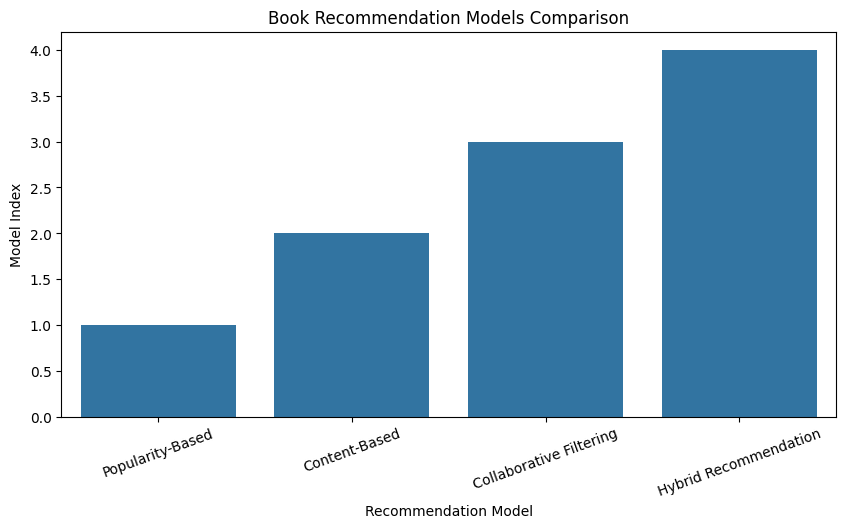

In [58]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x='Recommendation Model',
    y=[1, 2, 3, 4],
    data=comparison
)

plt.title("Book Recommendation Models Comparison")
plt.xlabel("Recommendation Model")
plt.ylabel("Model Index")

plt.xticks(rotation=20)
plt.show()

In [59]:
final_recommendations = popular_recommendations(100)

final_recommendations.to_csv(
    '/kaggle/working/book_recommendations.csv',
    index=False
)

print("Recommendations saved successfully!")

Recommendations saved successfully!
